In [2]:
1+1

2

In [3]:
from datasets import load_dataset

dataset = load_dataset("intro/flickr8k")

print(dataset)

Resolving data files:   0%|          | 0/6001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/6001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1001 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'split', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 6000
    })
    dev: Dataset({
        features: ['image', 'split', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['image', 'split', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
        num_rows: 1000
    })
})


In [4]:
from datasets import config

print("Dataset cache:", config.HF_DATASETS_CACHE)

Dataset cache: C:\Users\Lenovo\.cache\huggingface\datasets


In [5]:
dataset.save_to_disk(
    r"D:\Doc\Text-To-Image\dataset\flickr8k"
)

Saving the dataset (0/2 shards):   0%|          | 0/6000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1000 [00:00<?, ? examples/s]

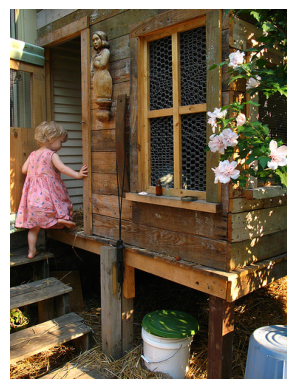

A child in a pink dress is climbing up a set of stairs in an entry way .
A girl going into a wooden building .
A little girl climbing into a wooden playhouse .
A little girl climbing the stairs to her playhouse .
A little girl in a pink dress going into a wooden cabin .


In [6]:
import matplotlib.pyplot as plt

sample = dataset["train"][0]

plt.imshow(sample["image"])
plt.axis("off")
plt.show()

for i in range(5):
    print(sample[f"caption_{i}"])

In [7]:
print(dataset["train"].column_names)

['image', 'split', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4']


In [8]:
import numpy as np
from PIL import Image

IMG_SIZE = 64

def preprocess_image(image):
    image = image.convert("RGB")
    image = image.resize((IMG_SIZE, IMG_SIZE))

    image = np.array(image, dtype=np.float32)

    image = (image / 127.5) - 1.0

    return image

In [9]:
image = preprocess_image(dataset["train"][0]["image"])

print("Shape:", image.shape)
print("Minimum:", image.min())
print("Maximum:", image.max())

Shape: (64, 64, 3)
Minimum: -1.0
Maximum: 1.0


In [10]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

MAX_TOKENS = 10000
MAX_LENGTH = 32

vectorizer = TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH
)

caption_columns = [
    c for c in dataset["train"].column_names
    if c.startswith("caption_")
]

captions = [
    caption
    for row in dataset["train"]
    for col in caption_columns
    if isinstance((caption := row[col]), str)
]

vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(captions).batch(256)
)

In [13]:
text = ["A brown dog running on grass"]

tokens = vectorizer(text)

print(tokens.numpy())

[[ 2 24  8 31  5 40  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
   0  0  0  0  0  0  0  0]]


In [41]:
import numpy as np

images = []
texts = []

for sample in dataset["train"]:

    image = preprocess_image(sample["image"])

    images.append(image)
    texts.append(sample["caption_0"])

images = np.stack(images).astype("float32")

text_tokens = vectorizer(
    tf.constant(texts)
).numpy()

print("Images:", images.shape)
print("Text tokens:", text_tokens.shape)

Images: (6000, 64, 64, 3)
Text tokens: (6000, 32)


In [15]:
import tensorflow as tf
from tensorflow.keras import layers, Model

MAX_TOKENS = 10000
MAX_LENGTH = 32
EMBEDDING_DIM = 128


def build_text_encoder():

    text_input = layers.Input(
        shape=(MAX_LENGTH,),
        dtype="int32",
        name="text_input"
    )

    # Convert each token into 128 numerical values
    x = layers.Embedding(
        input_dim=MAX_TOKENS,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    )(text_input)

    # Process the sequence of word embeddings
    x = layers.GRU(
        128
    )(x)

    # Generate final text representation
    output = layers.Dense(
        128,
        activation="linear"
    )(x)

    model = Model(
        inputs=text_input,
        outputs=output,
        name="Text_Encoder"
    )

    return model


text_encoder = build_text_encoder()

text_encoder.summary()

Model: "Text_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_input          │ (None, 32)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 32, 128)   │  1,280,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 32)        │          0 │ text_input[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 128)       │     99,072 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     16,512 │ gru[0][0]         │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,395,584 (5.32 MB)

 Trainable params: 1,395,584 (5.32 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
text_embeddings = text_encoder(
    text_tokens,
    training=False
)

print("Text tokens shape:", text_tokens.shape)
print("Text embeddings shape:", text_embeddings.shape)

Text tokens shape: (100, 32)
Text embeddings shape: (100, 128)


In [17]:
print("Original caption:")
print(texts[0])

print("\nToken IDs:")
print(text_tokens[0])

print("\nText embedding:")
print(text_embeddings[0].numpy())

Original caption:
A child in a pink dress is climbing up a set of stairs in an entry way .

Token IDs:
[   2   42    3    2   87  171    6  117   55    2  397   11  396    3
   27 6700  641    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0]

Text embedding:
[-0.01171502 -0.01052309  0.02066909  0.01159992  0.01058322  0.01050063
 -0.00208362  0.0002492  -0.01903203  0.01447744 -0.00720202 -0.00564923
  0.00756308  0.0009235   0.00933138  0.01335691  0.00467624 -0.02244951
 -0.00435781  0.01328794  0.00300011  0.00806689 -0.0174822   0.00387147
 -0.00230684 -0.00845148  0.00980047 -0.02316472  0.01588559 -0.01056766
  0.01014539 -0.00529611 -0.00294044 -0.01076238 -0.00653241 -0.0049225
  0.00468205 -0.01025189  0.01394786 -0.00598347  0.00221097 -0.01066387
  0.00719162  0.01307744  0.0183745   0.01475168 -0.01200583 -0.00053508
  0.0092789  -0.02111666 -0.00369828  0.00812556  0.00709572  0.00106059
  0.00694736  0.00472338  0.01601636 -0.01567207  0.00186749

In [19]:
import tensorflow as tf

TIMESTEPS = 1000

betas = tf.linspace(0.0001, 0.02, TIMESTEPS)

alphas = 1.0 - betas

alpha_bars = tf.math.cumprod(alphas)

print("Betas shape:", betas.shape)
print("Alpha bars shape:", alpha_bars.shape)

Betas shape: (1000,)
Alpha bars shape: (1000,)


In [20]:
def forward_diffusion(images, timesteps):

    images = tf.convert_to_tensor(images, dtype=tf.float32)
    timesteps = tf.convert_to_tensor(timesteps, dtype=tf.int32)

    # Generate Gaussian noise
    noise = tf.random.normal(tf.shape(images))

    # Get alpha_bar for each timestep
    alpha_bar = tf.gather(alpha_bars, timesteps)

    # Reshape for broadcasting across image dimensions
    alpha_bar = tf.reshape(alpha_bar, (-1, 1, 1, 1))

    # Add noise to images
    noisy_images = (
        tf.sqrt(alpha_bar) * images
        + tf.sqrt(1.0 - alpha_bar) * noise
    )

    return noisy_images, noise

In [21]:
images.shape

(100, 64, 64, 3)

In [22]:
original_image = images[0:1]

timesteps = tf.constant([500], dtype=tf.int32)

noisy_image, actual_noise = forward_diffusion(
    original_image,
    timesteps
)

print("Original:", original_image.shape)
print("Noisy:", noisy_image.shape)
print("Actual noise:", actual_noise.shape)

Original: (1, 64, 64, 3)
Noisy: (1, 64, 64, 3)
Actual noise: (1, 64, 64, 3)


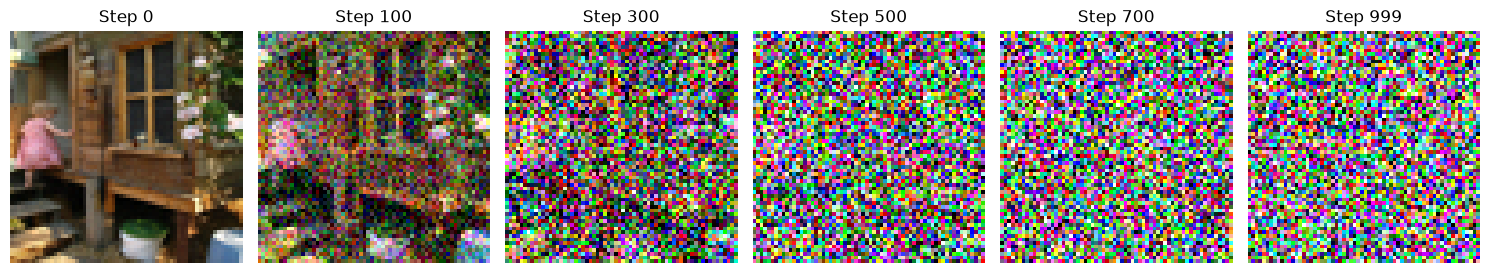

In [23]:
import matplotlib.pyplot as plt

steps = [0, 100, 300, 500, 700, 999]

plt.figure(figsize=(15, 3))

for i, t in enumerate(steps):

    timestep = tf.constant([t], dtype=tf.int32)

    noisy_image, _ = forward_diffusion(
        images[0:1],
        timestep
    )

    # Convert from [-1, 1] to [0, 1]
    display_image = (noisy_image[0].numpy() + 1) / 2
    display_image = np.clip(display_image, 0, 1)

    plt.subplot(1, len(steps), i + 1)

    plt.imshow(display_image)
    plt.title(f"Step {t}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
from tensorflow.keras import layers

def conv_block(x, filters):

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    return x

In [25]:
import tensorflow as tf
from tensorflow.keras import layers, Model

def build_conditional_unet():

    # Three inputs
    image_input = layers.Input(
        shape=(64, 64, 3),
        name="noisy_image"
    )

    timestep_input = layers.Input(
        shape=(1,),
        name="timestep"
    )

    text_input = layers.Input(
        shape=(128,),
        name="text_embedding"
    )

    # Normalize timestep to approximately [0, 1]
    t = layers.Rescaling(1.0 / 999.0)(timestep_input)

    # Combine timestep and text information
    condition = layers.Concatenate()([
        text_input,
        t
    ])

    condition = layers.Dense(
        128,
        activation="swish"
    )(condition)

    # Encoder block 1
    c1 = conv_block(image_input, 32)

    p1 = layers.MaxPooling2D()(c1)

    # Encoder block 2
    c2 = conv_block(p1, 64)

    p2 = layers.MaxPooling2D()(c2)

    # Bottleneck
    b = conv_block(p2, 128)

    # Convert condition to 128 feature values
    condition_features = layers.Dense(
        128
    )(condition)

    condition_features = layers.Reshape(
        (1, 1, 128)
    )(condition_features)

    # Add conditioning information to bottleneck
    b = layers.Add()([
        b,
        condition_features
    ])

    # Decoder block 1
    u1 = layers.UpSampling2D()(b)

    u1 = layers.Concatenate()([
        u1,
        c2
    ])

    u1 = conv_block(u1, 64)

    # Decoder block 2
    u2 = layers.UpSampling2D()(u1)

    u2 = layers.Concatenate()([
        u2,
        c1
    ])

    u2 = conv_block(u2, 32)

    # Predict RGB noise
    output = layers.Conv2D(
        3,
        kernel_size=1,
        padding="same",
        activation="linear"
    )(u2)

    return Model(
        inputs=[
            image_input,
            timestep_input,
            text_input
        ],
        outputs=output,
        name="Conditional_UNet"
    )

In [26]:
unet = build_conditional_unet()

unet.summary()

Model: "Conditional_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ noisy_image         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        896 │ noisy_image[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ timestep            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_embedding      │ (None, 128)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 1)         │          0 │ timestep[0][0]    │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 129)       │          0 │ text_embedding[0… │
│ (Concatenate)       │                   │            │ rescaling[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     16,640 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     16,512 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 128) │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 16, 16,    │          0 │ conv2d_5[0][0],   │
│                     │ 128)              │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 32, 32,    │          0 │ add[0][0]       

 Total params: 504,771 (1.93 MB)

 Trainable params: 504,771 (1.93 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
print("Inputs:", unet.input_shape)
print("Output:", unet.output_shape)

Inputs: [(None, 64, 64, 3), (None, 1), (None, 128)]
Output: (None, 64, 64, 3)


In [29]:
images.shape
# (100, 64, 64, 3)

text_embeddings.shape
# (100, 128)

TensorShape([100, 128])

In [30]:
# Select four images
batch_images = tf.convert_to_tensor(
    images[:4],
    dtype=tf.float32
)

# Select four text token sequences
batch_tokens = tf.convert_to_tensor(
    text_tokens[:4],
    dtype=tf.int32
)

# Generate random timesteps
timesteps = tf.random.uniform(
    shape=(4,),
    minval=0,
    maxval=1000,
    dtype=tf.int32
)

# Apply forward diffusion
noisy_images, actual_noise = forward_diffusion(
    batch_images,
    timesteps
)

# Generate text embeddings
batch_text_embeddings = text_encoder(
    batch_tokens,
    training=False
)

# Predict noise
predicted_noise = unet(
    [
        noisy_images,
        tf.cast(tf.expand_dims(timesteps, -1), tf.float32),
        batch_text_embeddings
    ],
    training=False
)

print("Noisy images:", noisy_images.shape)
print("Actual noise:", actual_noise.shape)
print("Predicted noise:", predicted_noise.shape)

Noisy images: (4, 64, 64, 3)
Actual noise: (4, 64, 64, 3)
Predicted noise: (4, 64, 64, 3)


In [31]:
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001
)

In [32]:
@tf.function
def train_step(batch_images, batch_tokens):

    batch_size = tf.shape(batch_images)[0]

    # Random diffusion timesteps
    timesteps = tf.random.uniform(
        (batch_size,),
        minval=0,
        maxval=1000,
        dtype=tf.int32
    )

    # Add noise
    noisy_images, actual_noise = forward_diffusion(
        batch_images,
        timesteps
    )

    with tf.GradientTape() as tape:

        # Trainable text embeddings
        text_features = text_encoder(
            batch_tokens,
            training=True
        )

        # Predict noise
        predicted_noise = unet(
            [
                noisy_images,
                tf.cast(
                    tf.expand_dims(timesteps, -1),
                    tf.float32
                ),
                text_features
            ],
            training=True
        )

        # Mean squared error
        loss = tf.reduce_mean(
            tf.square(actual_noise - predicted_noise)
        )

    # Train both networks
    variables = (
        text_encoder.trainable_variables
        + unet.trainable_variables
    )

    gradients = tape.gradient(
        loss,
        variables
    )

    optimizer.apply_gradients(
        zip(gradients, variables)
    )

    return loss

In [50]:
BATCH_SIZE = 32

train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        images.astype("float32"),
        text_tokens.astype("int32")
    )
)

train_dataset = (
    train_dataset
    .shuffle(6000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Total batches:", len(train_dataset))

Total batches: 188


In [51]:
import numpy as np
import matplotlib.pyplot as plt

EPOCHS = 10

loss_history = []

for epoch in range(EPOCHS):

    epoch_losses = []

    for batch_images, batch_tokens in train_dataset:

        loss = train_step(
            batch_images,
            batch_tokens
        )

        epoch_losses.append(float(loss.numpy()))

    avg_loss = np.mean(epoch_losses)

    loss_history.append(avg_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"- Loss: {avg_loss:.6f}"
    )

Epoch 1/10 - Loss: 0.083066
Epoch 2/10 - Loss: 0.074440
Epoch 3/10 - Loss: 0.077100
Epoch 4/10 - Loss: 0.076501
Epoch 5/10 - Loss: 0.072978
Epoch 6/10 - Loss: 0.072923
Epoch 7/10 - Loss: 0.072214
Epoch 8/10 - Loss: 0.073808
Epoch 9/10 - Loss: 0.064855
Epoch 10/10 - Loss: 0.068160


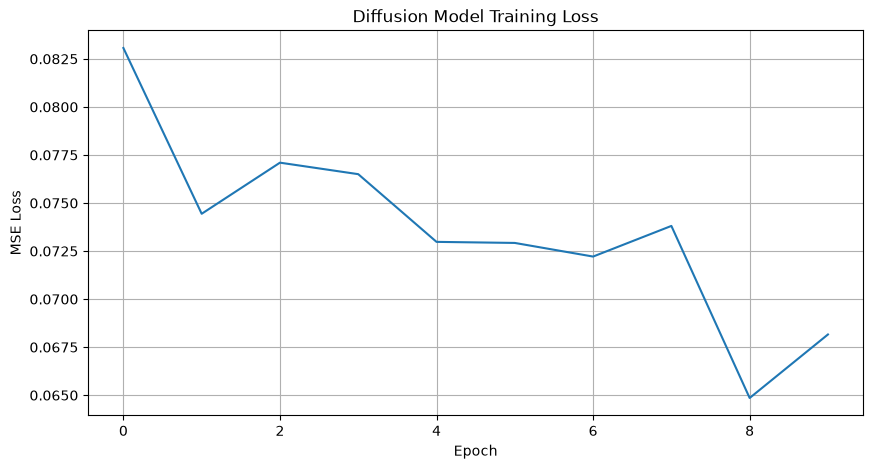

In [52]:
plt.figure(figsize=(10, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Diffusion Model Training Loss")

plt.grid(True)
plt.show()

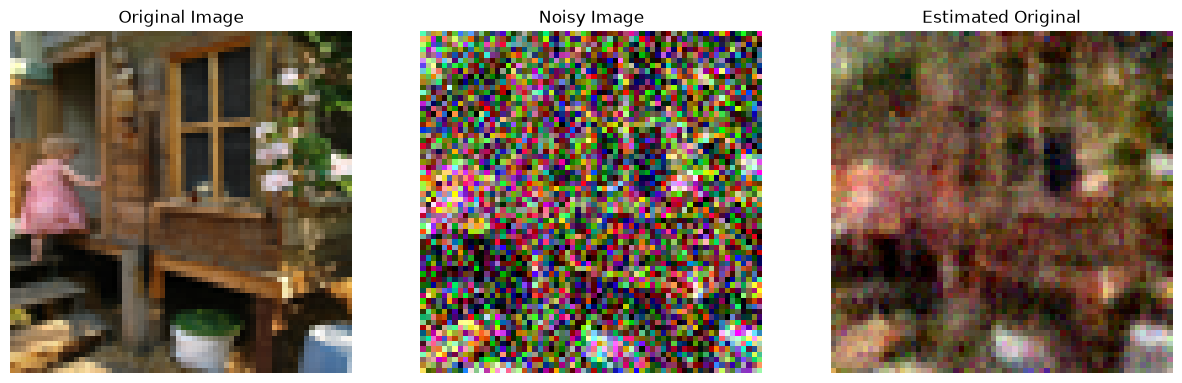

In [53]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Select one original image
original_image = tf.convert_to_tensor(
    images[0:1],
    dtype=tf.float32
)

# Select corresponding caption
tokens = tf.convert_to_tensor(
    text_tokens[0:1],
    dtype=tf.int32
)

# Select diffusion timestep
t = 200

timesteps = tf.constant([t], dtype=tf.int32)

# Add Gaussian noise
noisy_image, actual_noise = forward_diffusion(
    original_image,
    timesteps
)

# Generate text embedding
text_embedding = text_encoder(
    tokens,
    training=False
)

# Predict noise
predicted_noise = unet(
    [
        noisy_image,
        tf.constant([[float(t)]], dtype=tf.float32),
        text_embedding
    ],
    training=False
)

# Recover an estimate of the original image
alpha_bar = alpha_bars[t]

estimated_original = (
    noisy_image
    - tf.sqrt(1.0 - alpha_bar) * predicted_noise
) / tf.sqrt(alpha_bar)

# Convert images to displayable range
def display_image(image):
    image = (image[0].numpy() + 1.0) / 2.0
    return np.clip(image, 0, 1)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(display_image(original_image))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(display_image(noisy_image))
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(display_image(estimated_original))
plt.title("Estimated Original")
plt.axis("off")

plt.show()

In [54]:
import tensorflow as tf

def reverse_diffusion_step(
    image,
    timestep,
    text_embedding
):

    # Prepare timestep for U-Net
    timestep_input = tf.constant(
        [[float(timestep)]],
        dtype=tf.float32
    )

    # Predict noise
    predicted_noise = unet(
        [
            image,
            timestep_input,
            text_embedding
        ],
        training=False
    )

    # Noise schedule values
    beta_t = betas[timestep]
    alpha_t = alphas[timestep]
    alpha_bar_t = alpha_bars[timestep]

    # DDPM reverse mean
    mean = (
        1.0 / tf.sqrt(alpha_t)
    ) * (
        image
        -
        (
            beta_t /
            tf.sqrt(1.0 - alpha_bar_t)
        ) * predicted_noise
    )

    # Add sampling noise except at the final step
    if timestep > 0:

        alpha_bar_prev = alpha_bars[timestep - 1]

        posterior_variance = (
            beta_t
            * (1.0 - alpha_bar_prev)
            / (1.0 - alpha_bar_t)
        )

        noise = tf.random.normal(
            tf.shape(image)
        )

        image = (
            mean
            + tf.sqrt(posterior_variance) * noise
        )

    else:
        image = mean

    return image

In [55]:
import numpy as np

def generate_image(prompt):

    # Step 1: Convert text into tokens
    tokens = vectorizer(
        tf.constant([prompt])
    )

    # Step 2: Generate text embedding
    text_embedding = text_encoder(
        tokens,
        training=False
    )

    print("Text embedding shape:", text_embedding.shape)

    # Step 3: Start with random Gaussian noise
    image = tf.random.normal(
        shape=(1, 64, 64, 3)
    )

    # Step 4: Reverse diffusion
    for timestep in reversed(range(TIMESTEPS)):

        image = reverse_diffusion_step(
            image,
            timestep,
            text_embedding
        )

        if timestep % 100 == 0:
            print(
                f"Remaining timestep: {timestep}"
            )

    # Step 5: Convert [-1, 1] to [0, 1]
    image = (image + 1.0) / 2.0

    # Keep valid RGB pixel values
    image = tf.clip_by_value(
        image,
        0.0,
        1.0
    )

    return image[0].numpy()

Text embedding shape: (1, 128)
Remaining timestep: 900
Remaining timestep: 800
Remaining timestep: 700
Remaining timestep: 600
Remaining timestep: 500
Remaining timestep: 400
Remaining timestep: 300
Remaining timestep: 200
Remaining timestep: 100
Remaining timestep: 0


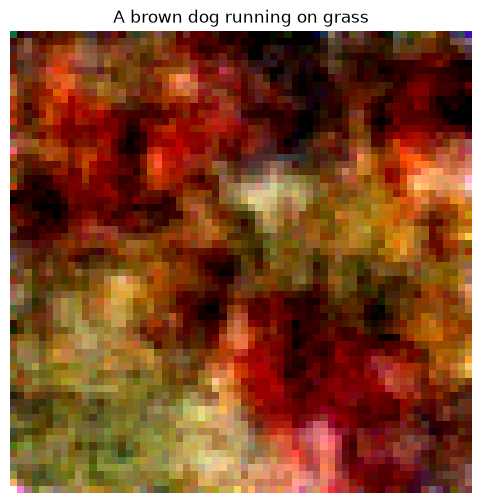

In [56]:
import matplotlib.pyplot as plt

prompt = "A brown dog running on grass"

generated_image = generate_image(prompt)

plt.figure(figsize=(6, 6))

plt.imshow(generated_image)

plt.title(prompt)

plt.axis("off")

plt.show()